In [3]:
import numpy as np, matplotlib.pyplot as plt
from scipy.optimize import minimize

np.random.seed(0)                       # remove for fully random runs; keep while writing the report
N = 100; half_n = N // 2
r_gt, x0_gt, y0_gt = 10, 2, 3
s = r_gt / 16
t = np.random.uniform(0, 2*np.pi, half_n)
n = s * np.random.randn(half_n)
X_circ = np.c_[x0_gt + (r_gt+n)*np.cos(t), y0_gt + (r_gt+n)*np.sin(t)]
m, b = -1, 2
x = np.linspace(-12, 12, half_n)
X_line = np.c_[x, m*x + b + 1.0*np.random.randn(half_n)]
X = np.vstack((X_circ, X_line))

In [4]:
rng = np.random.default_rng(1)

def line_from_two(p, q):
    d = q - p
    nrm = np.array([-d[1], d[0]]) / np.linalg.norm(d)    # unit normal: ||[a,b]|| = 1 by construction
    return nrm[0], nrm[1], nrm @ p                       # a, b, d  (ax + by = d)

def line_errors(P, a, b, d):
    return np.abs(P @ np.array([a, b]) - d)              # normal distance

def ransac_line(P, thresh=1.5, min_inliers=35, iters=300):
    best = dict(count=0)
    for _ in range(iters):
        i, j = rng.choice(len(P), 2, replace=False)
        a, b, d = line_from_two(P[i], P[j])
        inl = line_errors(P, a, b, d) < thresh
        if inl.sum() > best['count']:
            best = dict(count=inl.sum(), inl=inl, sample=P[[i, j]], model=(a, b, d))
    assert best['count'] >= min_inliers, "consensus too small"
    # refit on inliers by total least squares: normal = smallest singular vector
    Q = P[best['inl']]; mu = Q.mean(0)
    nrm = np.linalg.svd(Q - mu)[2][-1]                   # unit length, satisfies the constraint
    best['refit'] = (nrm[0], nrm[1], nrm @ mu)
    return best

line = ransac_line(X)
print("line inliers:", line['count'], " (a,b,d) =", np.round(line['refit'], 3))

line inliers: 55  (a,b,d) = [0.717 0.697 1.503]


In [5]:
def circle_from_three(p1, p2, p3):
    A = 2 * np.array([p2 - p1, p3 - p1])
    if abs(np.linalg.det(A)) < 1e-6: return None         # nearly collinear
    rhs = np.array([p2 @ p2 - p1 @ p1, p3 @ p3 - p1 @ p1])
    c = np.linalg.solve(A, rhs)
    return c, np.linalg.norm(p1 - c)

def circle_errors(P, c, r):
    return np.abs(np.linalg.norm(P - c, axis=1) - r)     # radial error

def fit_circle(Q, c0, r0):
    cost = lambda p: np.sum((np.linalg.norm(Q - p[:2], axis=1) - p[2])**2)
    res = minimize(cost, [c0[0], c0[1], r0])
    return res.x[:2], res.x[2]

def ransac_circle(P, thresh=1.5, min_inliers=30, iters=500):
    best = dict(count=0)
    for _ in range(iters):
        idx = rng.choice(len(P), 3, replace=False)
        out = circle_from_three(*P[idx])
        if out is None: continue
        c, r = out
        inl = circle_errors(P, c, r) < thresh
        if inl.sum() > best['count']:
            best = dict(count=inl.sum(), inl=inl, sample=P[idx], model=(c, r))
    assert best['count'] >= min_inliers, "consensus too small"
    best['refit'] = fit_circle(P[best['inl']], *best['model'])
    return best

remnant = X[~line['inl']]
circ = ransac_circle(remnant)
c_fit, r_fit = circ['refit']
print("circle inliers:", circ['count'], " centre", np.round(c_fit, 2), " radius", round(r_fit, 2))

circle inliers: 45  centre [1.86 3.07]  radius 9.95


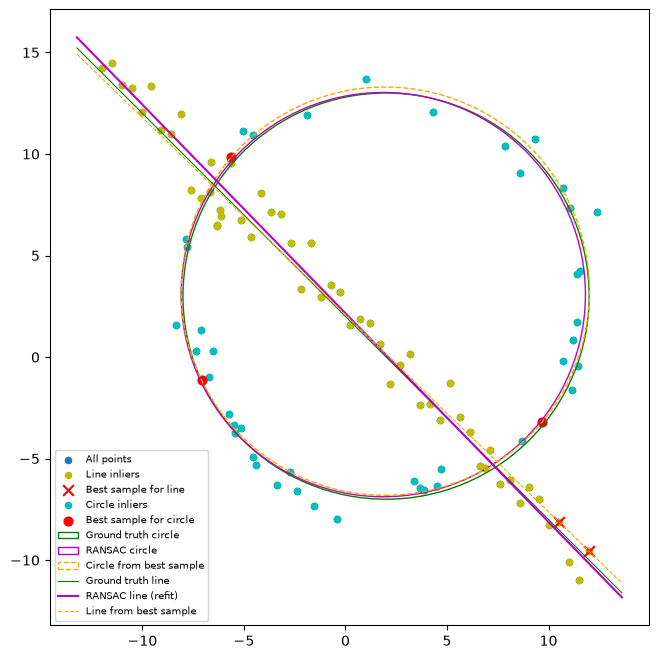

In [6]:
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(*X.T, s=20, label='All points')
ax.scatter(*X[line['inl']].T, c='y', s=20, label='Line inliers')
ax.scatter(*line['sample'].T, c='r', marker='x', s=60, label='Best sample for line')
rem_idx = np.where(~line['inl'])[0]
ax.scatter(*remnant[circ['inl']].T, c='c', s=20, label='Circle inliers')
ax.scatter(*circ['sample'].T, c='r', s=40, label='Best sample for circle')

ax.add_patch(plt.Circle((x0_gt, y0_gt), r_gt, color='g', fill=False, label='Ground truth circle'))
ax.add_patch(plt.Circle(c_fit, r_fit, color='m', fill=False, label='RANSAC circle'))
cs, rs = circ['model']
ax.add_patch(plt.Circle(cs, rs, color='orange', fill=False, ls='--', label='Circle from best sample'))

xs = np.array(ax.get_xlim())
ax.plot(xs, m*xs + b, c='g', lw=0.8, label='Ground truth line')
a_, b_, d_ = line['refit']
ax.plot(xs, (d_ - a_*xs)/b_, c='m', label='RANSAC line (refit)')
a_, b_, d_ = line['model']
ax.plot(xs, (d_ - a_*xs)/b_, c='orange', ls='--', lw=0.8, label='Line from best sample')
ax.set_aspect('equal'); ax.legend(fontsize=7); plt.show()

circle-first inliers: 60  radius 9.8  centre [2.  2.9]


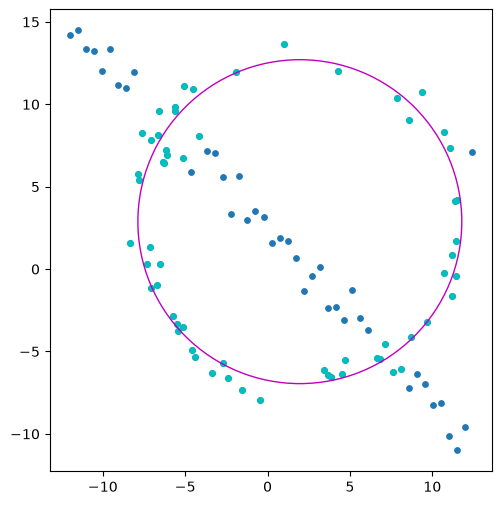

In [7]:
bad = ransac_circle(X, thresh=1.5, min_inliers=1)
print("circle-first inliers:", bad['count'], " radius", round(bad['refit'][1], 1), " centre", np.round(bad['refit'][0], 1))
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(*X.T, s=15); ax.scatter(*X[bad['inl']].T, c='c', s=15)
ax.add_patch(plt.Circle(*bad['refit'], color='m', fill=False)); ax.set_aspect('equal'); plt.show()